# Entraînement du modèle A – YOLOv8n (augmentations par défaut)

Projet : Détection et comptage de la faune africaine

Étape du cahier des charges : Étape 2 – Expérience A : modèle de référence

## Objectif

Entraîner un modèle YOLOv8n avec les augmentations standards de YOLOv8. Ce modèle sert de référence pour la comparaison avec le modèle B, dont les augmentations géométriques sont modifiées.

## Paramètres

Les modèles A et B ont les mêmes paramètres, sauf scale et translate.

| Paramètre | Modèle A | Modèle B |
|---|---|---|
| Modèle de départ | yolov8n.pt | yolov8n.pt |
| Résolution | 512 px | 512 px |
| Époques | 15 | 15 |
| Graine aléatoire (seed) | 42 | 42 |
| scale | 0.5 (défaut) | 0.2 |
| translate | 0.1 (défaut) | 0.05 |

Les partitions officielles du dataset sont conservées. Le jeu de test n'est pas utilisé ici : il est réservé à l'évaluation finale.

## Installation d'Ultralytics

Installation de la bibliothèque Ultralytics, qui fournit YOLOv8.

In [1]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 56.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


## Chargement du modèle pré-entraîné

yolov8n.pt est la version nano de YOLOv8, déjà entraînée sur le dataset COCO. C'est le point de départ des modèles A et B, qui partagent donc les mêmes poids initiaux.

In [2]:
from ultralytics import YOLO

model = YOLO('yolov8n.pt')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


## Entraînement du modèle A

Nous entraînons le modèle sur le dataset African Wildlife, avec les paramètres du projet :

- data : le dataset African Wildlife, téléchargé automatiquement par Ultralytics ;
- imgsz : les images sont redimensionnées à 512 × 512 pixels ;
- epochs : le modèle parcourt 15 fois les images d'entraînement ;
- seed : graine aléatoire fixée à 42, pour pouvoir reproduire l'expérience ;
- scale et translate : augmentations géométriques, laissées à leurs valeurs par défaut pour le modèle A (0.5 et 0.1) ;
- project et name : dossier où sont enregistrés les poids et les résultats.

À la fin de chaque époque, YOLO évalue le modèle sur la validation.

In [3]:
results = model.train(
    data='african-wildlife.yaml',
    imgsz=512,
    epochs=15,
    seed=42,
    scale=0.5,
    translate=0.1,
    project='runs',
    name='modele_A'
)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=african-wildlife.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=modele_A, nbs=64, nms=None, opset=None, optimize=False, optimizer=a

### Résultats et explication

L'entraînement de 15 époques a duré un peu plus de 3 minutes sur le GPU T4. Les métriques ci-dessous sont celles du meilleur modèle (best.pt) sur la validation, qui contient 225 images et 379 animaux.

| Classe | Précision | Rappel | mAP50 | mAP50-95 |
|---|---|---|---|---|
| Toutes les classes | 0.920 | 0.894 | 0.933 | 0.772 |
| buffalo | 0.955 | 0.854 | 0.937 | 0.782 |
| elephant | 0.859 | 0.890 | 0.916 | 0.733 |
| rhino | 0.940 | 0.927 | 0.939 | 0.814 |
| zebra | 0.926 | 0.904 | 0.940 | 0.758 |

Le résultat montre que le modèle apprend bien. Le mAP50 passe de 0.814 à la première époque à 0.931 à la dernière, et le mAP50-95 de 0.632 à 0.772. Les pertes d'entraînement diminuent : box_loss passe de 0.867 à 0.581 et cls_loss de 1.508 à 0.441. Le mAP50 baisse temporairement à l'époque 3 (0.591), puis il remonte.

Les quatre classes ont des mAP50 proches (de 0.916 à 0.940). L'éléphant a la précision la plus faible (0.859), le buffle a le rappel le plus faible (0.854) et le rhinocéros a le meilleur mAP50-95 (0.814). Ces valeurs servent de référence pour la comparaison avec le modèle B.

## Courbes d'entraînement

Ce graphique montre, époque après époque, les pertes d'entraînement et de validation, ainsi que la précision, le rappel et les mAP.

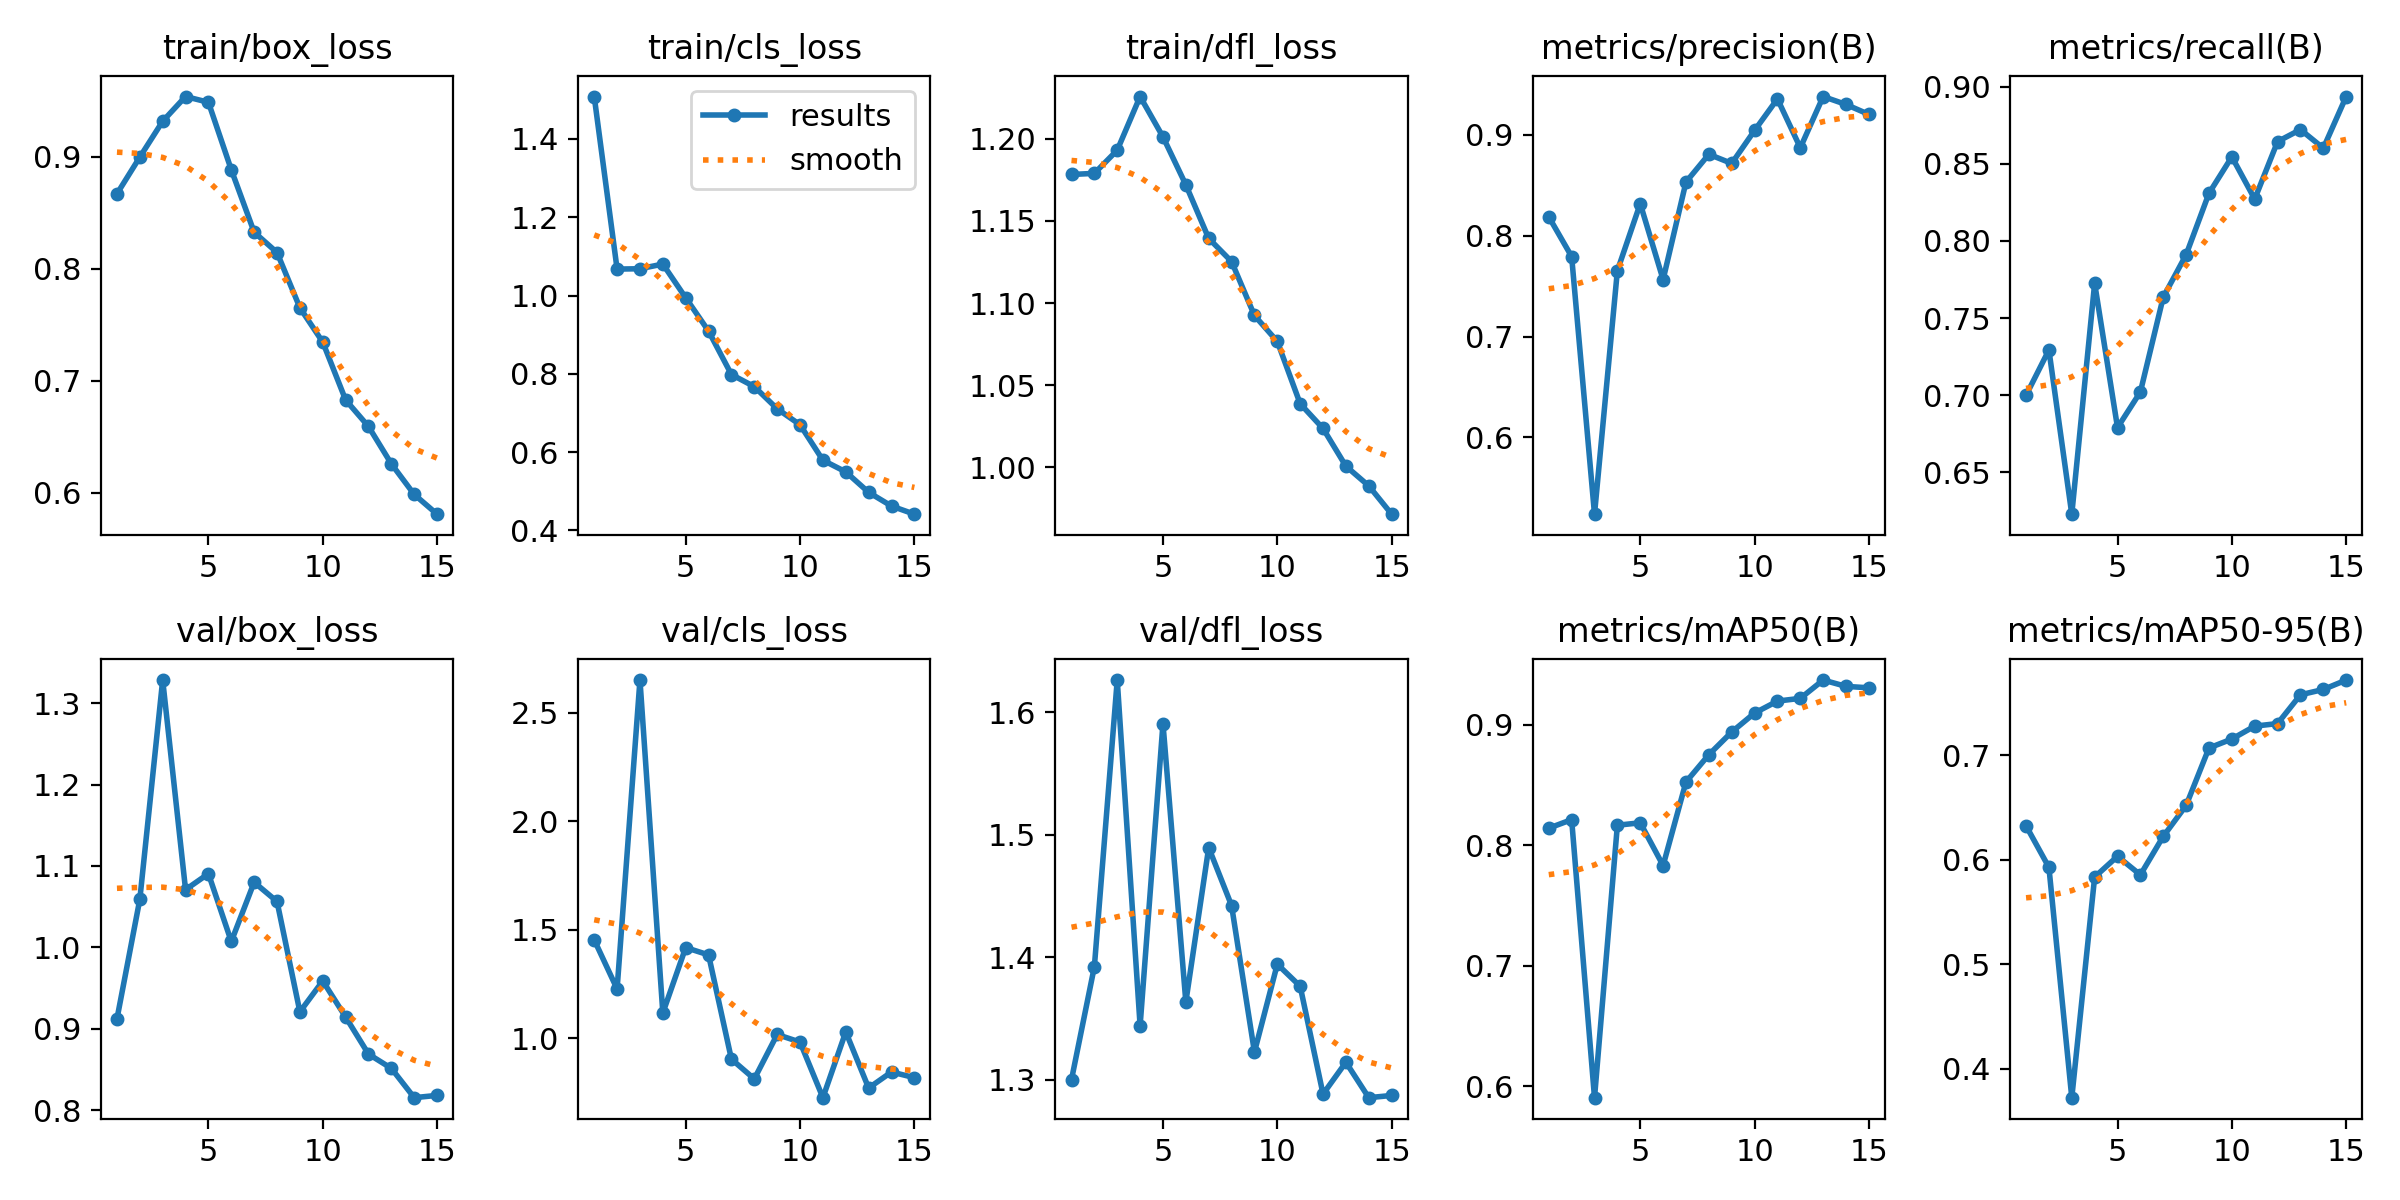

In [4]:
from IPython.display import Image, display

display(Image(filename=f'{model.trainer.save_dir}/results.png'))

### Résultats et explication

Les pertes d'entraînement diminuent à partir de l'époque 4 : box_loss passe d'environ 0.95 à 0.58, cls_loss de 1.5 à 0.44 et dfl_loss de 1.22 à 0.97. La précision et le rappel augmentent globalement, avec une forte baisse à l'époque 3.

Les pertes de validation sont instables au début, avec un pic à l'époque 3 (box_loss 1.33, cls_loss 2.65, dfl_loss 1.63). Ce pic correspond à la chute du mAP50 (0.59) et du mAP50-95 (0.37) à la même époque. Cette instabilité peut s'expliquer par la phase d'échauffement du début de l'entraînement (warmup_epochs = 3 dans les paramètres). Ensuite, les pertes de validation baissent et se stabilisent en suivant celles d'entraînement. Nous n'observons pas de surapprentissage : la perte de validation ne remonte pas à la fin de l'entraînement.

Le mAP50 se stabilise autour de 0.93 à partir de l'époque 13, tandis que le mAP50-95 augmente encore jusqu'à 0.772 à l'époque 15. Le modèle n'a donc peut-être pas totalement convergé, mais le nombre d'époques est fixé à 15 par le projet.

## Matrice de confusion

La matrice de confusion indique, pour chaque classe réelle, ce que le modèle a prédit. La diagonale correspond aux bonnes prédictions.

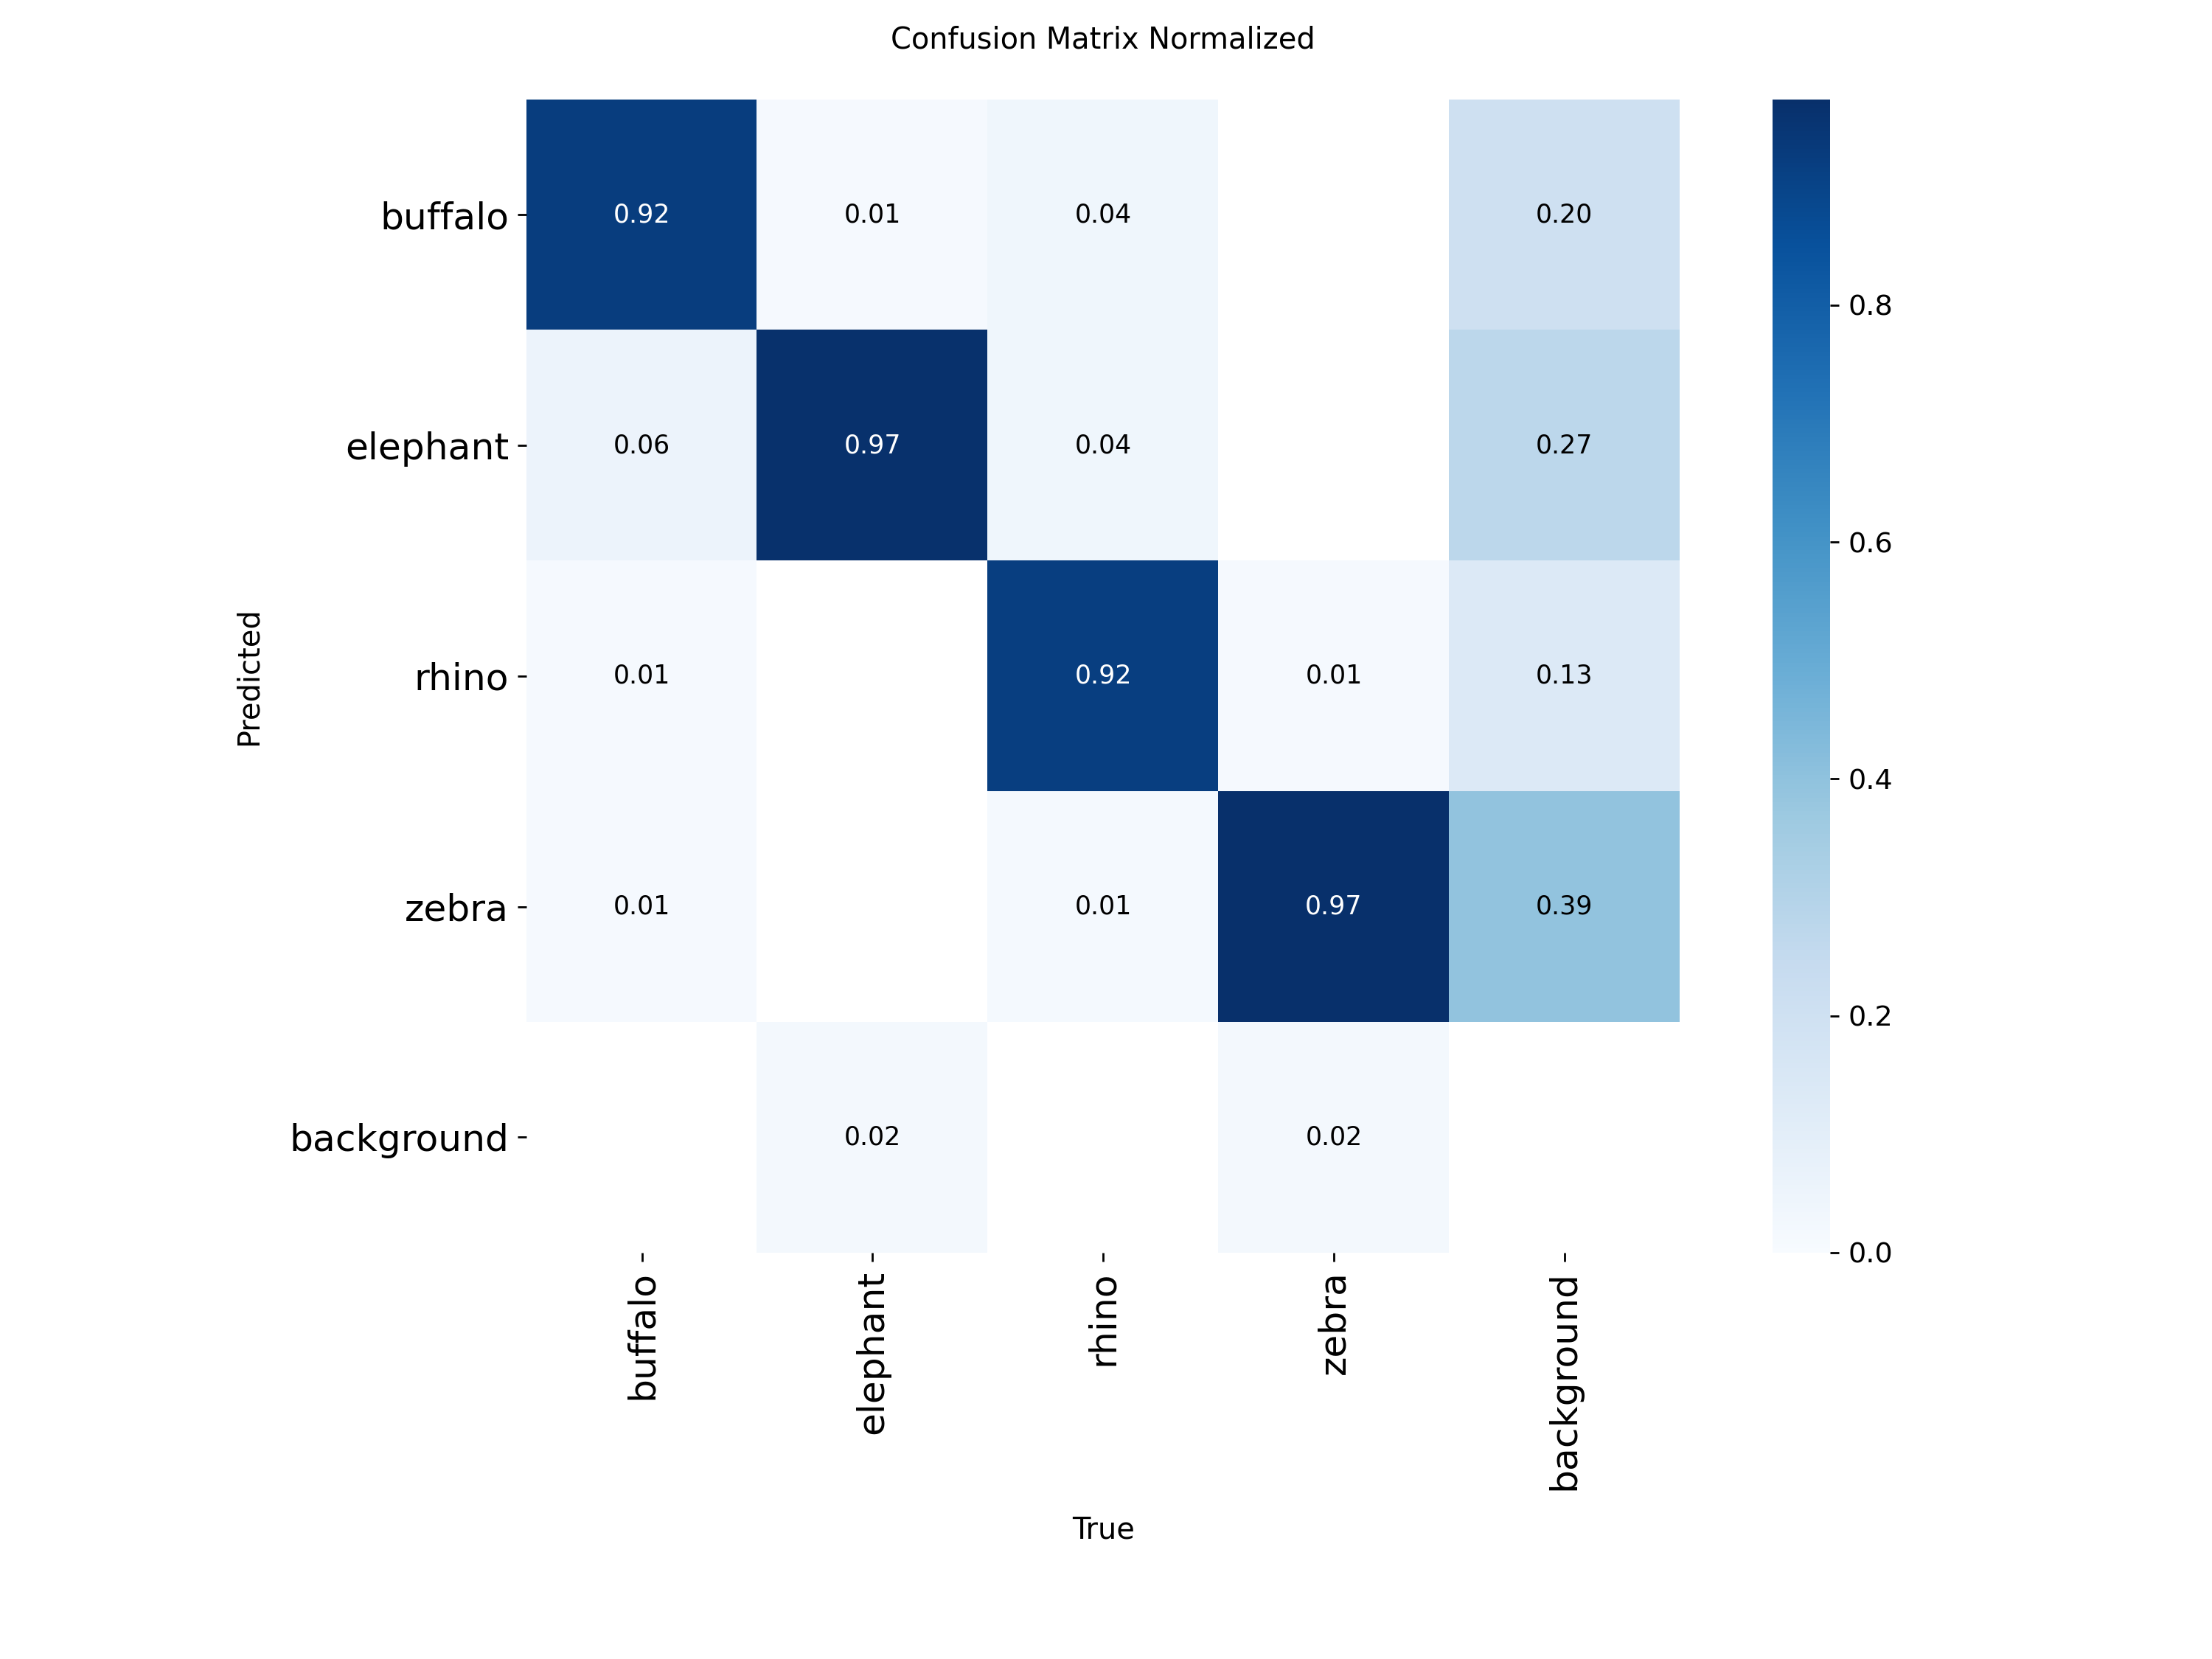

In [5]:
display(Image(filename=f'{model.trainer.save_dir}/confusion_matrix_normalized.png'))

### Résultats et explication

La matrice est normalisée par colonne : chaque colonne correspond à la classe réelle (True) et chaque ligne à la prédiction du modèle. La diagonale contient les bonnes prédictions : 0.97 pour l'éléphant et le zèbre, 0.92 pour le buffle et le rhinocéros.

Les confusions entre classes sont faibles. La plus importante concerne les buffles réels prédits comme des éléphants (0.06). Les rhinocéros réels sont parfois prédits comme des buffles ou des éléphants (0.04 pour chacun).

La colonne background correspond aux zones sans animal où le modèle prédit pourtant un animal (fausses détections). Elles se répartissent entre le zèbre (0.39), l'éléphant (0.27), le buffle (0.20) et le rhinocéros (0.13). La ligne background correspond aux animaux non détectés : 0.02 pour l'éléphant et pour le zèbre.